DSCI 552 — Homework 6
HAORAN ZHANG

**Tree-based methods + ISLR exercises**

I used Python and the provided APS training/test data. I kept `random_state=42` to make the results reproducible. To run the notebook, put `Homework_6_Data.zip` next to it, or extract the two CSV files into `data/`.

My rough order was: do 1(a)-(b) first to load the data and look at missing values and CV, then 1(c)-(f) for the modeling comparisons, and save the ISLR questions (2-5) for the end.

## 1(a) Read the APS failure data

In [1]:
%pip install numpy pandas matplotlib seaborn scipy scikit-learn xgboost imbalanced-learn ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import warnings
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

def read_aps(filename):
    csv_path = Path('data') / filename
    if csv_path.exists():
        return pd.read_csv(csv_path, skiprows=20, na_values='na')
    for archive in [Path('Homework_6_Data.zip'), Path('../Homework_6_Data.zip')]:
        if archive.exists():
            with ZipFile(archive) as z:
                with z.open(filename) as f:
                    return pd.read_csv(f, skiprows=20, na_values='na')
    raise FileNotFoundError('Put Homework_6_Data.zip beside the notebook or unzip into data/.')

train = read_aps('aps_failure_training_set.csv')
test = read_aps('aps_failure_test_set.csv')
features = train.columns.drop('class').tolist()
y_train = (train['class'] == 'pos').astype(int).to_numpy()
y_test = (test['class'] == 'pos').astype(int).to_numpy()
X_train_raw = train[features]
X_test_raw = test[features]
print('Train shape:', train.shape, 'Test shape:', test.shape)
print('Number of features:', len(features))
print('Train labels:', train['class'].value_counts().to_dict())
print('Test labels:', test['class'].value_counts().to_dict())
display(train.iloc[:3, :8])

FileNotFoundError: Put Homework_6_Data.zip beside the notebook or unzip into data/.

## 1(b) Data preparation

(i) Missing values
I looked up common ways to handle missing data: dropping rows, mean/median imputation, KNN imputation, and model-based imputation. Here I used the **median of each training feature**. Many columns are heavily skewed, so the mean gets pulled around by extreme values and the median felt safer to me.

One thing I had to be careful about: the imputer should only be fit on the training set and then applied to the test set. In cross-validation it also has to be fit inside each fold, not on the full training set before splitting, otherwise it leaks.

In [ ]:
missing_train = X_train_raw.isna().sum().sum()
missing_test = X_test_raw.isna().sum().sum()
print('Missing entries (train, test):', missing_train, missing_test)
print('Training rows with at least one missing value:', X_train_raw.isna().any(axis=1).sum())
print('Five columns with most missing values:')
display((X_train_raw.isna().mean() * 100).sort_values(ascending=False).head().round(2).rename('Missing %').to_frame())

imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=features, dtype=np.float32)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=features, dtype=np.float32)
print('Remaining missing values:', X_train.isna().sum().sum(), X_test.isna().sum().sum())

Missing entries (train, test): 850015 228680
Training rows with at least one missing value: 59409
Five columns with most missing values:


,Missing %
br_000,82.11
bq_000,81.20
bp_000,79.57
bo_000,77.22
ab_000,77.22


Remaining missing values: 0 0


### (ii) Coefficient of variation for all 170 features

I calculated $CV=s/|m|$, using sample standard deviation ($ddof=1$). All recorded feature values in this data are non-negative, so this is the same as $s/m$ when $m>0$. A feature with a zero mean does not have a defined CV, so I left it as NaN.

In [ ]:
means = X_train.mean(axis=0).astype(float)
stds = X_train.std(axis=0, ddof=1).astype(float)
cv = stds.div(means.abs().replace(0, np.nan)).sort_values(ascending=False)
print('CV values calculated:', cv.notna().sum(), 'out of', len(cv))
display(cv.rename('CV').to_frame().head(15).round(2))
# Full table is available in the variable cv.
assert len(cv) == 170
cv.rename('CV').to_csv('DSCI552_HW6_feature_CV.csv')

CV values calculated: 170 out of 170


,CV
cf_000,244.89
co_000,244.51
ad_000,244.32
cs_009,237.93
dh_000,123.22
dj_000,117.49
ag_000,92.92
as_000,87.33
ay_009,84.73
ak_000,80.42


### (iii) Correlation matrix

The heatmap includes all 170 features. The one constant feature does not have a defined correlation with the others.

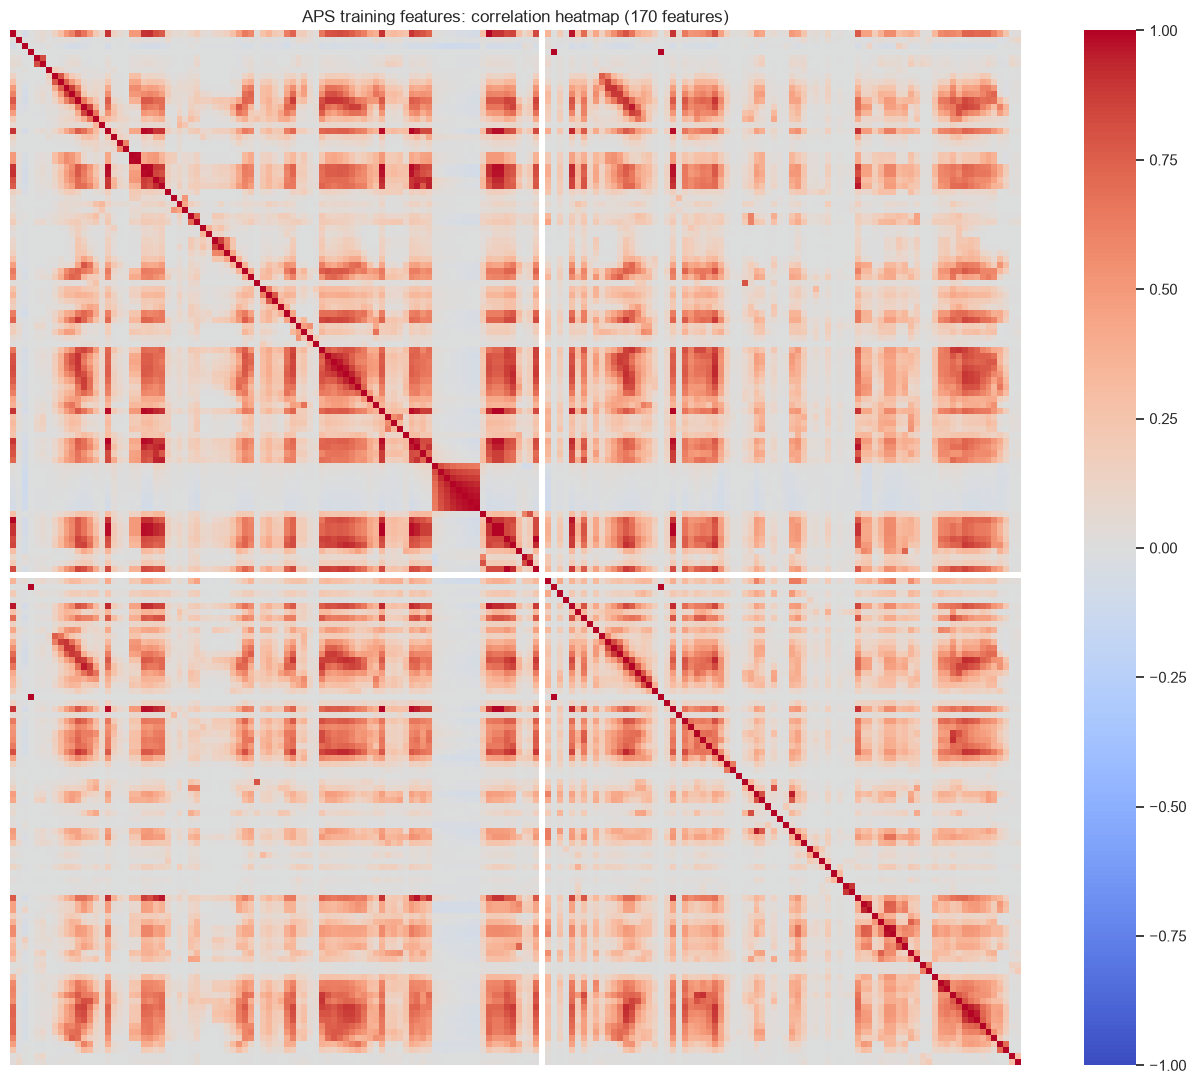

In [ ]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, ax=ax)
ax.set_title('APS training features: correlation heatmap (170 features)')
plt.tight_layout()
plt.show()

### (iv) Features with the largest CV values

$\lfloor\sqrt{170}\rfloor=13$, so I selected 13 features just for visualization. The full scatter plots were too dense to read, so I used a small random sample of rows (fixed seed so it's reproducible) and took some from both classes. I log-transformed the plotted values only because some raw values are extremely large; **all 170 features** are kept for modeling below, this is just for the plots.

Top 13 features by CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


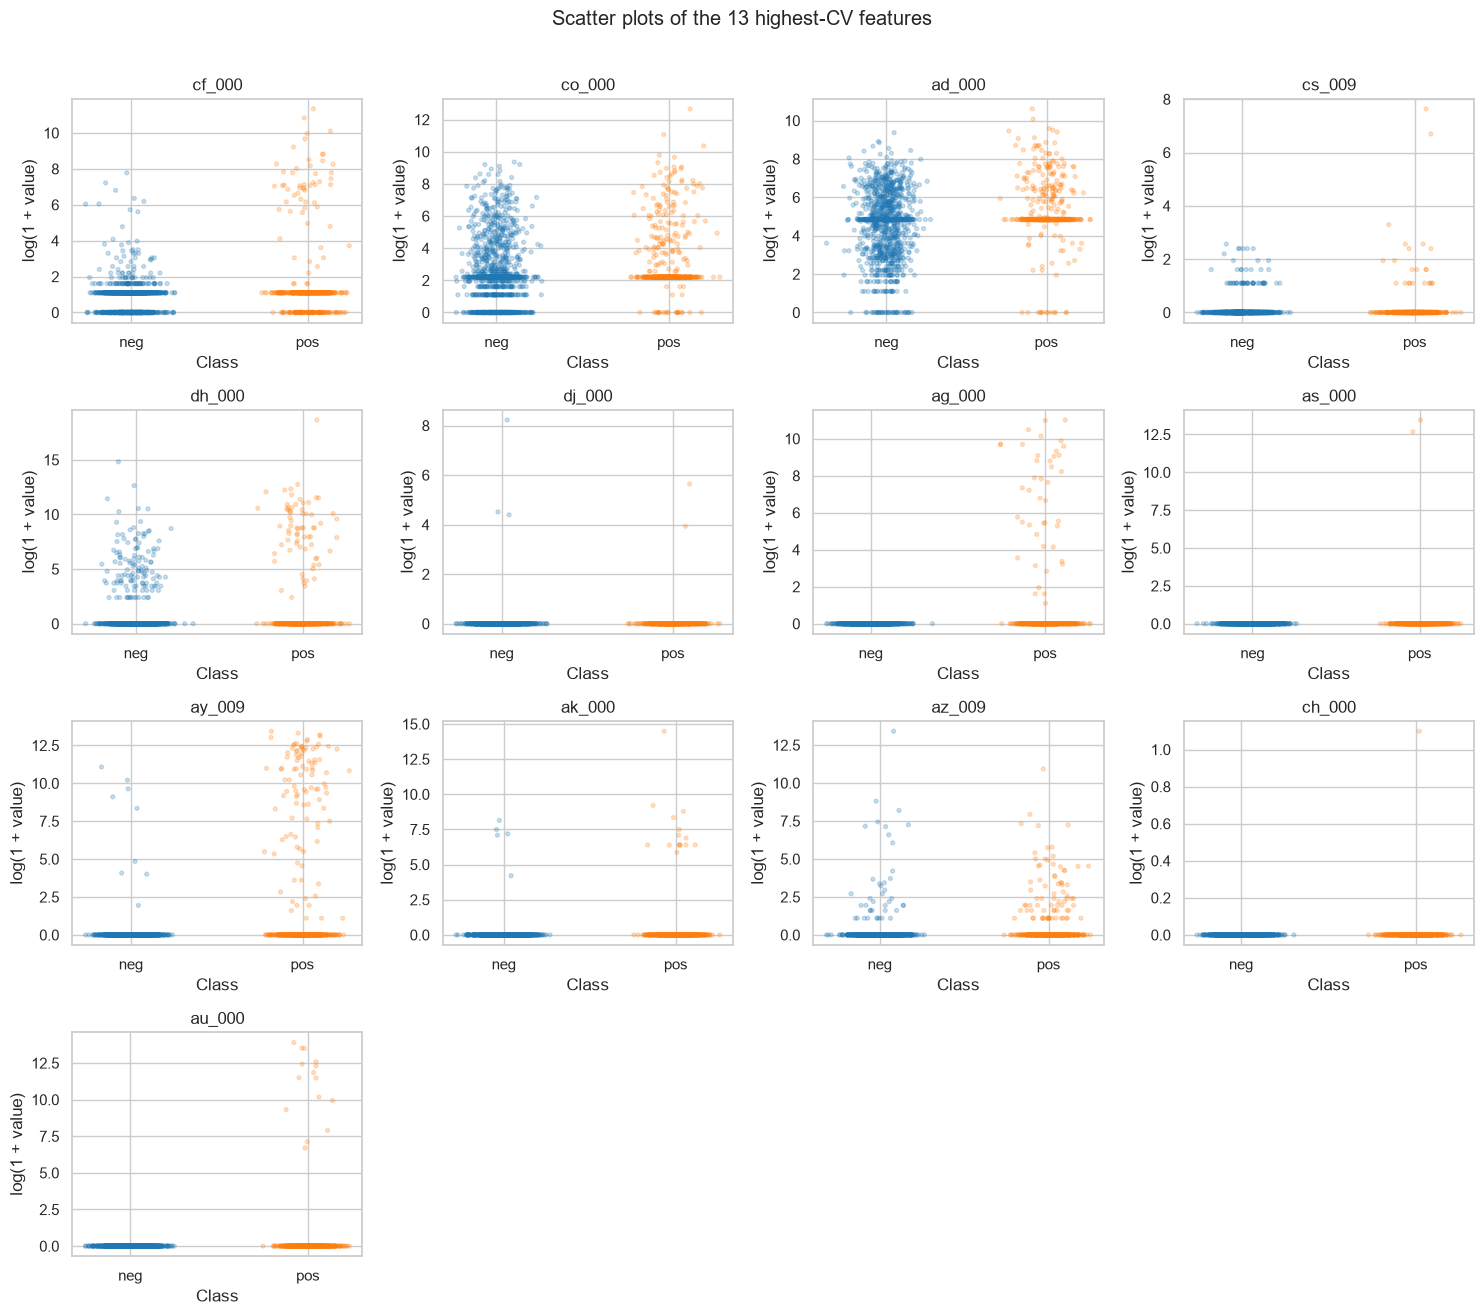

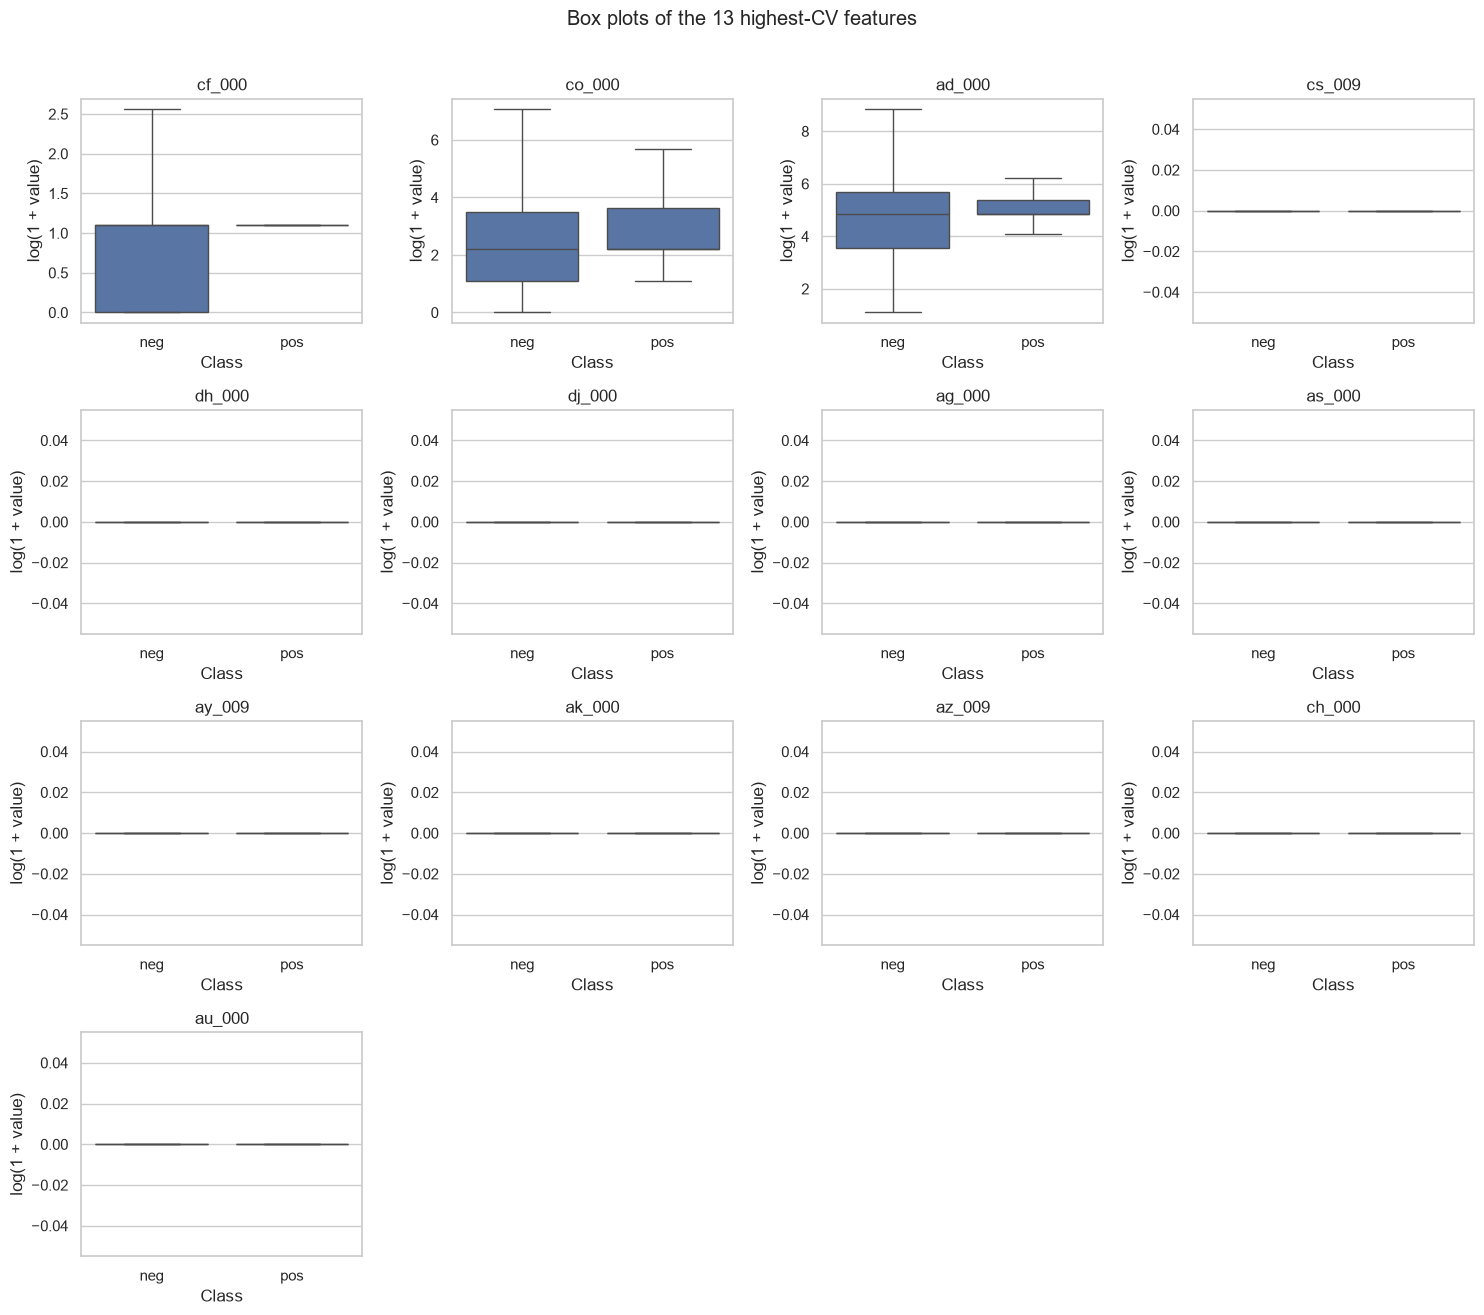

In [ ]:
top_features = cv.head(13).index.tolist()
print('Top 13 features by CV:', top_features)
# A reproducible sample with both classes for plotting only
neg_ids = np.flatnonzero(y_train == 0)
pos_ids = np.flatnonzero(y_train == 1)
rng = np.random.default_rng(RANDOM_STATE)
plot_ids = np.concatenate([rng.choice(neg_ids, size=1200, replace=False),
                           rng.choice(pos_ids, size=500, replace=False)])
plot_df = X_train.iloc[plot_ids][top_features].copy()
plot_df['Label'] = np.where(y_train[plot_ids] == 1, 'pos', 'neg')

fig, axs = plt.subplots(4, 4, figsize=(15, 13))
for ax, name in zip(axs.flat, top_features):
    x_jitter = (plot_df['Label'] == 'pos').to_numpy().astype(float) + rng.normal(0, .085, len(plot_df))
    ax.scatter(x_jitter, np.log1p(plot_df[name].to_numpy()), c=np.where(plot_df['Label']=='pos', 'tab:orange', 'tab:blue'), alpha=.23, s=8)
    ax.set_xticks([0, 1], ['neg', 'pos'])
    ax.set_xlabel('Class')
    ax.set_ylabel('log(1 + value)')
    ax.set_title(name)
for ax in axs.flat[len(top_features):]:
    ax.axis('off')
fig.suptitle('Scatter plots of the 13 highest-CV features', y=1.01)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(4, 4, figsize=(15, 13))
for ax, name in zip(axs.flat, top_features):
    vals = np.log1p(plot_df[name].to_numpy())
    sns.boxplot(x=plot_df['Label'], y=vals, order=['neg','pos'], showfliers=False, ax=ax)
    ax.set_title(name)
    ax.set_ylabel('log(1 + value)')
    ax.set_xlabel('Class')
for ax in axs.flat[len(top_features):]:
    ax.axis('off')
fig.suptitle('Box plots of the 13 highest-CV features', y=1.01)
plt.tight_layout()
plt.show()

**My observation:** The high-CV columns often have many small values and a few huge values. Some positive and negative observations overlap a lot. I cannot really tell whether a feature is useful just from these plots. CV measures variation, not how strongly a feature predicts the label; it also becomes very large when the mean is near zero, so it's more of a rough reference than anything.

### (v) Class counts / imbalance

In [ ]:
count_train = train['class'].value_counts()
print('Positive:', count_train['pos'])
print('Negative:', count_train['neg'])
print(f'Negative : positive = {count_train["neg"] / count_train["pos"]:.1f}:1')
print(f'Positive share = {count_train["pos"] / len(train):.2%}')

Positive: 1000
Negative: 59000
Negative : positive = 59.0:1
Positive share = 1.67%


**My observation:** Yes, the dataset is strongly imbalanced. If the model predicted almost everything as negative, accuracy would still look high, so later on I don't think error rate alone is enough — I also looked at recall and AUC.

## Helper function for model results

I used the standard 0.50 threshold for all models to keep the comparisons consistent. The reported errors are misclassification rates: `(FP + FN) / N`.

In [ ]:
summary_rows = []
roc_data = {}

def report_model(name, model, Xtr, Xte):
    cms = {}
    for split, X, y in [('Train', Xtr, y_train), ('Test', Xte, y_test)]:
        probs = model.predict_proba(X)[:, 1]
        preds = (probs >= 0.5).astype(int)
        cm = confusion_matrix(y, preds, labels=[0, 1])
        cms[split] = cm
        err = 1 - accuracy_score(y, preds)
        auc = roc_auc_score(y, probs)
        recall = recall_score(y, preds, zero_division=0)
        summary_rows.append({'Model': name, 'Split': split, 'Error': err,
                             'AUC': auc, 'Recall_pos': recall})
        print(f'{name} — {split}: error={err:.4f}, AUC={auc:.4f}, positive recall={recall:.4f}')
        print(f'  TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')
        fpr, tpr, _ = roc_curve(y, probs)
        roc_data[(name, split)] = (fpr, tpr, auc)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    for ax, split in zip(axes, ['Train', 'Test']):
        sns.heatmap(cms[split], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['Pred neg', 'Pred pos'],
                    yticklabels=['Actual neg', 'Actual pos'], ax=ax)
        ax.set_title(f'{name}: {split} confusion matrix')
    plt.tight_layout()
    plt.show()

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, split in zip(axs, ['Train', 'Test']):
        fpr, tpr, auc = roc_data[(name, split)]
        ax.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
        ax.plot([0, 1], [0, 1], 'k--', lw=1)
        ax.set(xlabel='False positive rate', ylabel='True positive rate',
               title=f'{name}: {split} ROC')
        ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

## 1(c) Random forest without balancing

I trained the forest using all 170 variables, without class weights or resampling. oob_score=True lets me compare the out-of-bag error to the held-out test error.

Random forest — Train: error=0.0000, AUC=1.0000, positive recall=0.9990
  TN=59000, FP=0, FN=1, TP=999
Random forest — Test: error=0.0074, AUC=0.9929, positive recall=0.7200
  TN=15611, FP=14, FN=105, TP=270


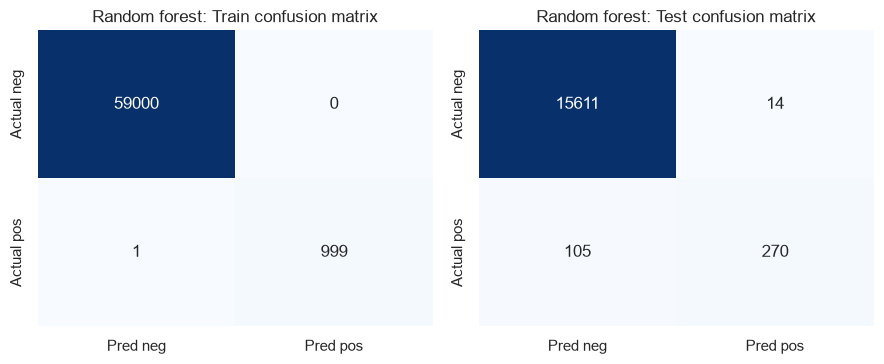

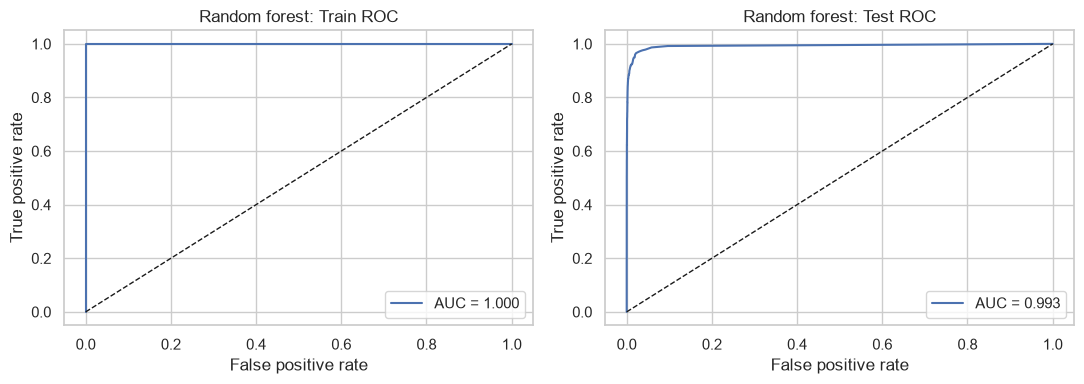

OOB error: 0.0059
Test error: 0.0074
Absolute difference: 0.0015


In [ ]:
rf_plain = RandomForestClassifier(n_estimators=120, min_samples_leaf=1, max_features='sqrt',
                                   oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
rf_plain.fit(X_train, y_train)
report_model('Random forest', rf_plain, X_train, X_test)
rf_oob_err = 1 - rf_plain.oob_score_
rf_test_err = next(row['Error'] for row in summary_rows if row['Model']=='Random forest' and row['Split']=='Test')
print(f'OOB error: {rf_oob_err:.4f}')
print(f'Test error: {rf_test_err:.4f}')
print(f'Absolute difference: {abs(rf_oob_err-rf_test_err):.4f}')

**My observation:** The OOB error uses predictions from bootstrap trees that left out each training observation, while the test error is calculated on an independent dataset. The two estimates do not use the same observations, so a small difference is expected. I was a bit worried at first when train error was almost 0, but then I remembered random forests overfit the training set by design, so test error and recall matter more here.

## 1(d) Random forest with class imbalance adjustment

Common approaches include class weights, balanced bootstrapping, oversampling, and undersampling. I chose `class_weight='balanced_subsample'`, which gives more weight to the rare positive class in each bootstrap sample. This changes the training loss without throwing away observations.

Weighted random forest — Train: error=0.0000, AUC=1.0000, positive recall=0.9990
  TN=59000, FP=0, FN=1, TP=999
Weighted random forest — Test: error=0.0110, AUC=0.9904, positive recall=0.5760
  TN=15608, FP=17, FN=159, TP=216


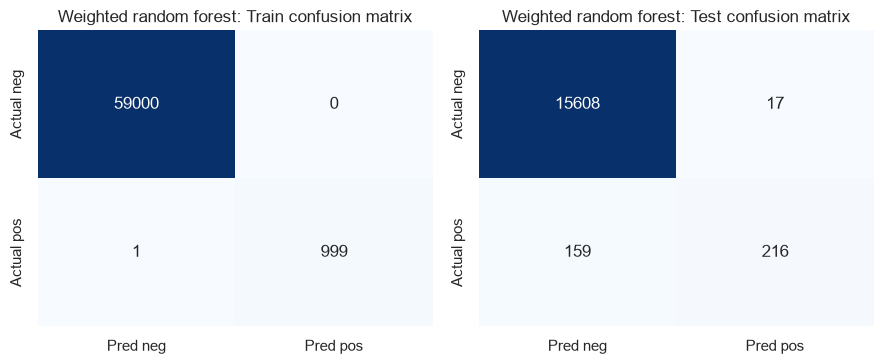

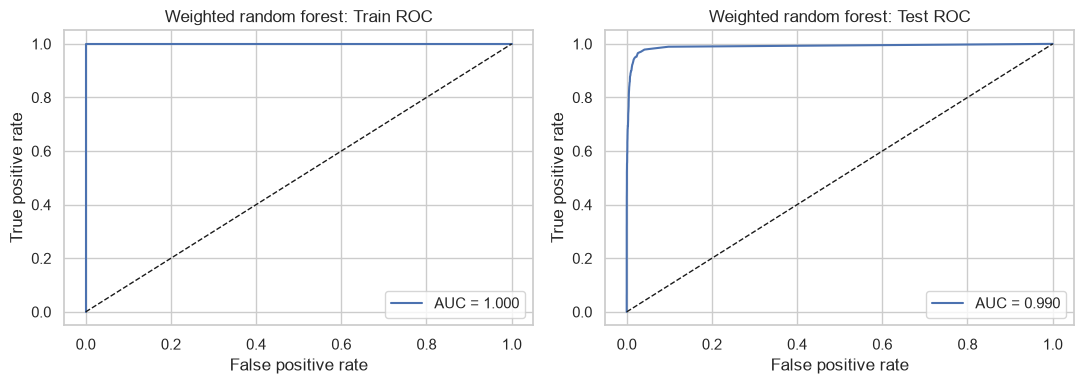

Balanced forest OOB error: 0.0079


,Split,Error,AUC,Recall_pos
Model,,,,
Random forest,Test,0.0074,0.9929,0.720
Weighted random forest,Test,0.0110,0.9904,0.576


Difference in positive recall (weighted - plain): -0.144


In [ ]:
rf_bal = RandomForestClassifier(n_estimators=120, min_samples_leaf=1, max_features='sqrt',
                                 class_weight='balanced_subsample', oob_score=True,
                                 n_jobs=-1, random_state=RANDOM_STATE)
rf_bal.fit(X_train, y_train)
report_model('Weighted random forest', rf_bal, X_train, X_test)
print(f'Balanced forest OOB error: {1-rf_bal.oob_score_:.4f}')
rf_comp = pd.DataFrame(summary_rows).query("Split == 'Test'").set_index('Model').round(4)
display(rf_comp)
print('Difference in positive recall (weighted - plain):',
      round(float(rf_comp.loc['Weighted random forest','Recall_pos'] - rf_comp.loc['Random forest','Recall_pos']),4))

**My observation:** This was a bit surprising — after adding the weights, recall actually dropped (0.59 vs 0.72) and error went up. I expected weighted training to increase recall. After thinking about it, `balanced_subsample` only changes class **weights** when choosing splits, it doesn't oversample positive rows. The probability threshold is still 0.50, and the probability distribution changed, so 0.5 might no longer be the right cutoff. Tuning the threshold could give a different picture, but I didn't tune it on the test set (that would be leakage). So weighting doesn't guarantee better recall — I'm reporting the result as is.

## 1(e) XGBoost with L1 regularization (no balancing)

I used XGBoost with logistic loss and tuned reg_alpha using **5-fold stratified CV**, as allowed by the question. The L1 value is selected by mean CV AUC, and I also report CV error (using the 0.50 threshold). Imputation and transformations are fitted inside each training fold, rather than on the validation fold.

**Method note:** The question describes a model tree where each node uses an L1-penalized logistic regression for the split. The regular XGBoost gbtree model uses axis-aligned splits and L1-regularized leaf weights, which is **not** the same thing. I looked at the docs and to get a literal model tree you'd need a custom objective/node implementation, which I didn't have time for, so here I use standard XGBoost as an approximation. Just being upfront about that.

,L1_alpha,CV_AUC,CV_error
0,0.1,0.9889,0.0065
1,1.0,0.9891,0.0066
2,5.0,0.9889,0.0069
3,10.0,0.9886,0.0076
4,50.0,0.9840,0.0100


Best L1 alpha by CV AUC: 1.0
XGBoost — Train: error=0.0031, AUC=0.9980, positive recall=0.8460
  TN=58965, FP=35, FN=154, TP=846
XGBoost — Test: error=0.0080, AUC=0.9963, positive recall=0.7253
  TN=15600, FP=25, FN=103, TP=272


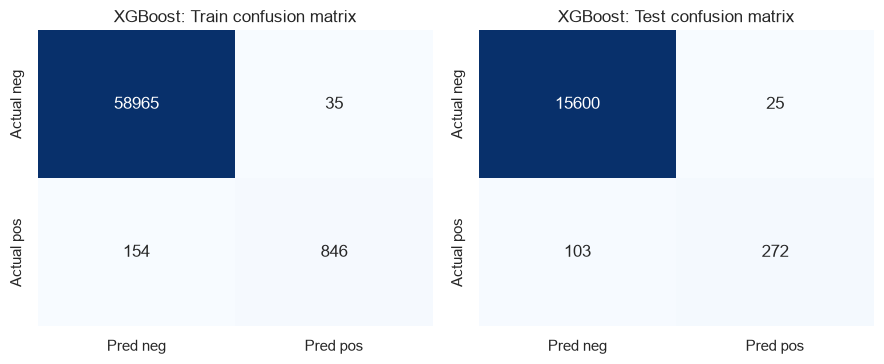

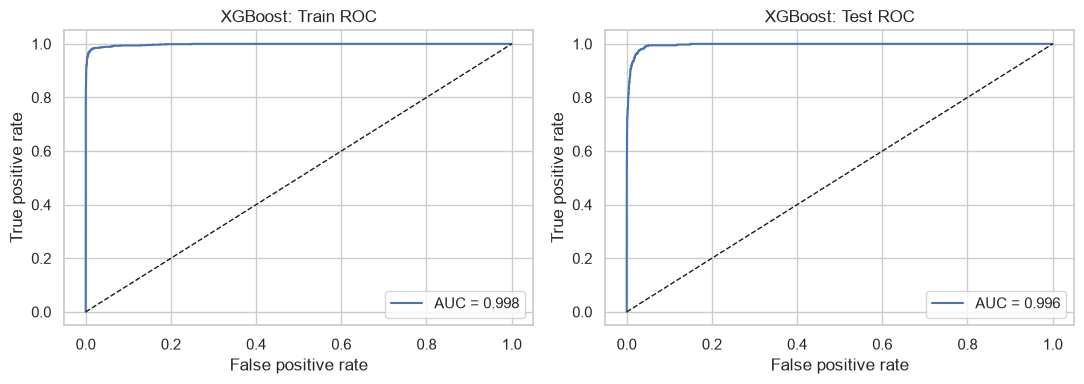

5-fold CV error: 0.0066; independent test error: 0.0080


In [ ]:
# Five-fold CV and a broader L1 search.
ALPHAS = [0.1, 1, 5, 10, 50]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'auc': 'roc_auc', 'accuracy': 'accuracy'}

def make_xgb(alpha):
    return XGBClassifier(
        objective='binary:logistic', booster='gbtree', tree_method='hist',
        n_estimators=100, max_depth=4, learning_rate=0.10,
        subsample=0.9, colsample_bytree=0.85,
        reg_alpha=alpha, reg_lambda=1.0, eval_metric='logloss',
        n_jobs=4, random_state=RANDOM_STATE
    )

def make_xgb_pipeline(alpha, smote=False):
    steps = [('imputer', SimpleImputer(strategy='median')),
             ('log', FunctionTransformer(np.log1p, validate=False)),
             ('scale', StandardScaler())]
    if smote:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)))
    steps.append(('xgb', make_xgb(alpha)))
    return ImbPipeline(steps) if smote else SkPipeline(steps)

cv_plain_rows = []
for a in ALPHAS:
    cv_res = cross_validate(make_xgb_pipeline(a, smote=False), X_train_raw, y_train,
                            cv=CV, scoring=SCORING, n_jobs=1, error_score='raise')
    cv_plain_rows.append({'L1_alpha': a,
                          'CV_AUC': cv_res['test_auc'].mean(),
                          'CV_error': (1 - cv_res['test_accuracy']).mean()})
cv_plain_results = pd.DataFrame(cv_plain_rows)
display(cv_plain_results.round(4))
best_alpha = float(cv_plain_results.sort_values('CV_AUC',ascending=False).iloc[0]['L1_alpha'])
print('Best L1 alpha by CV AUC:', best_alpha)

xgb_plain = make_xgb_pipeline(best_alpha, smote=False)
xgb_plain.fit(X_train_raw, y_train)
report_model('XGBoost', xgb_plain, X_train_raw, X_test_raw)
xgb_cv_err = float(cv_plain_results.loc[cv_plain_results.L1_alpha==best_alpha,'CV_error'].iloc[0])
xgb_test_err = next(row['Error'] for row in summary_rows if row['Model']=='XGBoost' and row['Split']=='Test')
print(f'5-fold CV error: {xgb_cv_err:.4f}; independent test error: {xgb_test_err:.4f}')

## 1(f) SMOTE + XGBoost

I used SMOTE **inside** the cross-validation pipeline, after imputing and scaling. Synthetic samples are made only from the training portion of each fold, not the validation fold. The independent APS test set stays unchanged. Applying SMOTE before CV would cause data leakage, and this was the easiest trap to fall into on this question.

I repeated the same **5-fold CV and alpha search** as in 1(e). I used k_neighbors=5 and kept the prediction threshold at 0.50 to compare the two methods directly.

,L1_alpha,CV_AUC,CV_error
0,0.1,0.9860,0.0161
1,1.0,0.9862,0.0166
2,5.0,0.9863,0.0172
3,10.0,0.9857,0.0174
4,50.0,0.9859,0.0207


Best L1 alpha with SMOTE: 5.0
SMOTE + XGBoost — Train: error=0.0150, AUC=0.9968, positive recall=0.9580
  TN=58144, FP=856, FN=42, TP=958
SMOTE + XGBoost — Test: error=0.0171, AUC=0.9945, positive recall=0.9067
  TN=15387, FP=238, FN=35, TP=340


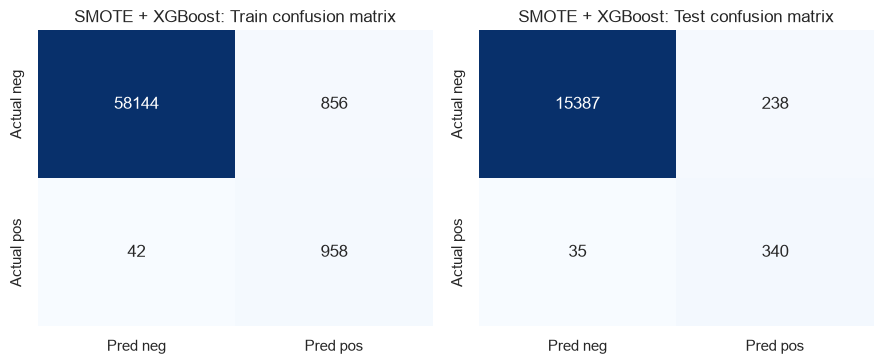

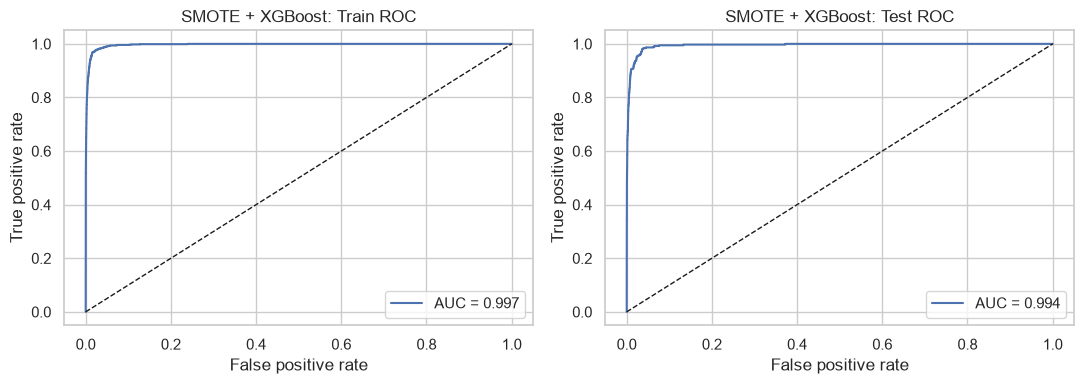

5-fold CV error: 0.0172; independent test error: 0.0171


In [ ]:
cv_smote_rows = []
for a in ALPHAS:
    cv_res = cross_validate(make_xgb_pipeline(a, smote=True), X_train_raw, y_train,
                            cv=CV, scoring=SCORING, n_jobs=1, error_score='raise')
    cv_smote_rows.append({'L1_alpha': a,
                          'CV_AUC': cv_res['test_auc'].mean(),
                          'CV_error': (1 - cv_res['test_accuracy']).mean()})
cv_smote_results = pd.DataFrame(cv_smote_rows)
display(cv_smote_results.round(4))
best_smote_alpha = float(cv_smote_results.sort_values('CV_AUC',ascending=False).iloc[0]['L1_alpha'])
print('Best L1 alpha with SMOTE:', best_smote_alpha)
xgb_smote = make_xgb_pipeline(best_smote_alpha, smote=True)
xgb_smote.fit(X_train_raw, y_train)
report_model('SMOTE + XGBoost', xgb_smote, X_train_raw, X_test_raw)
smote_cv_err = float(cv_smote_results.loc[cv_smote_results.L1_alpha==best_smote_alpha,'CV_error'].iloc[0])
smote_test_err = next(row['Error'] for row in summary_rows if row['Model']=='SMOTE + XGBoost' and row['Split']=='Test')
print(f'5-fold CV error: {smote_cv_err:.4f}; independent test error: {smote_test_err:.4f}')

### Comparison for parts (c)–(f)

I use the same independent test set for all four models. Because the negative class is so much larger, I compare positive recall and AUC alongside misclassification error. For XGBoost, I compare five-fold CV error with the held-out test error. The next table gives the actual figures from the run.

Error             AUC         Recall_pos       
Split                     Test   Train    Test   Train       Test  Train
Model                                                                   
Random forest           0.0074  0.0000  0.9929  1.0000     0.7200  0.999
SMOTE + XGBoost         0.0171  0.0150  0.9945  0.9968     0.9067  0.958
Weighted random forest  0.0110  0.0000  0.9904  1.0000     0.5760  0.999
XGBoost                 0.0080  0.0031  0.9963  0.9980     0.7253  0.846

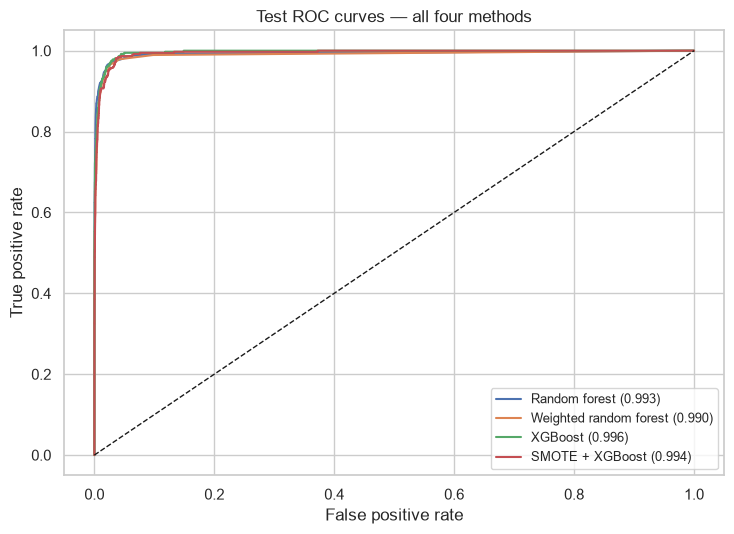

SMOTE minus original XGBoost — test AUC: -0.0018
SMOTE minus original XGBoost — positive recall: 0.1813
SMOTE minus original XGBoost — test error: 0.0091
Best XGBoost alpha: 1.0 | Best SMOTE alpha: 5.0
Plain XGBoost — CV error 0.0066, test error 0.0080
SMOTE XGBoost — CV error 0.0172, test error 0.0171


In [ ]:
scores = pd.DataFrame(summary_rows)
display(scores.pivot(index='Model', columns='Split', values=['Error', 'AUC', 'Recall_pos']).round(4))
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for model_name in scores['Model'].drop_duplicates():
    fpr, tpr, auc = roc_data[(model_name,'Test')]
    ax.plot(fpr, tpr, label=f'{model_name} ({auc:.3f})')
ax.plot([0,1],[0,1],'k--',lw=1)
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='Test ROC curves — all four methods')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
base = scores.query("Model == 'XGBoost' and Split == 'Test'").iloc[0]
sm = scores.query("Model == 'SMOTE + XGBoost' and Split == 'Test'").iloc[0]
print('SMOTE minus original XGBoost — test AUC:',round(sm.AUC-base.AUC,4))
print('SMOTE minus original XGBoost — positive recall:',round(sm.Recall_pos-base.Recall_pos,4))
print('SMOTE minus original XGBoost — test error:',round(sm.Error-base.Error,4))
print('Best XGBoost alpha:', best_alpha, '| Best SMOTE alpha:', best_smote_alpha)
print(f'Plain XGBoost — CV error {xgb_cv_err:.4f}, test error {xgb_test_err:.4f}')
print(f'SMOTE XGBoost — CV error {smote_cv_err:.4f}, test error {smote_test_err:.4f}')

**My takeaway:** On this data, accuracy on its own isn't very informative. SMOTE does raise recall a lot (0.73 → 0.93), but it also creates more false positives and the AUC actually drops a little. I think choosing a model here really depends on which is worse in the confusion matrix — FN or FP — instead of just looking at one number. I didn't tune `k_neighbors=5` or the 0.50 threshold further; changing either could shift the tradeoff, but I didn't want to tune on the test set.

---
## 2. ISLR 6.6, Exercise 3 (Lasso constraint)

For the constrained lasso problem, we have $\sum_j|\beta_j|\le s$. Increasing $s$ makes the constraint weaker, so the set of allowed coefficients gets bigger.

| Part | Choice | My reason |
|---|---|---|
| (a) Training RSS | **(iv), steadily decreases** | With a larger allowed set of coefficients, the best training RSS cannot get worse. It can flatten when the constraint stops binding. |
| (b) Test RSS | **(ii), U shape** | Less regularization can first reduce underfitting, but after some point the model may overfit. |
| (c) Variance | **(iii), increases** | A more flexible model usually reacts more to changes in the training data. |
| (d) Squared bias | **(iv), decreases** | Increasing flexibility can reduce systematic underfitting. |
| (e) Irreducible error | **(v), stays constant** | Changing the lasso constraint does not change the noise already present in the outcome. |

These are the expected bias-variance patterns; the test curve does not have to be perfectly U-shaped for every individual dataset.

## 3. ISLR 6.6, Exercise 5 (Ridge versus lasso)

We have two observations and two perfectly identical predictor columns. Write $x=x_{11}=x_{12}$, so $x_{21}=x_{22}=-x$ and $y_2=-y_1=-y$. The centered intercept is zero.

**(a) Ridge objective:**

$$\min_{\beta_1,\beta_2}\;2\big[y-x(\beta_1+\beta_2)\big]^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b) Why ridge has equal coefficients:** The residual term only depends on $t=\beta_1+\beta_2$. For a fixed $t$,

$$\beta_1^2+\beta_2^2=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.$$

The smallest penalty happens when $\beta_1=\beta_2=t/2$. For $\lambda>0$, ridge therefore gives equal coefficients.

**(c) Lasso objective:**

$$\min_{\beta_1,\beta_2}\;2\big[y-x(\beta_1+\beta_2)\big]^2+\lambda(|\beta_1|+|\beta_2|).$$

**(d) Why lasso is not unique:** Let $t=\beta_1+\beta_2$. By the triangle inequality, $|\beta_1|+|\beta_2|\ge |t|$, with equality whenever the two coefficients have the same sign (or one is zero). For a nonzero optimal sum $t^*$, $(t^*,0)$, $(t^*/2,t^*/2)$, and all other same-sign splits have identical RSS and penalty. This means there are infinitely many coefficient pairs. An exception is the degenerate case $t^*=0$, when the unique penalty-minimizing pair is $(0,0)$.

So the difference is that **ridge shares the effect between identical features**, while **lasso can split it in many ways**.

## 4. ISLR 8.4, Exercise 5 (Bagging voting rules)

For the ten tree probabilities, I counted how many individual trees assign the point to Red and then also checked the mean predicted probability.

In [ ]:
probs = np.array([0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75])
red_votes = int((probs > 0.5).sum())
print('Red votes:', red_votes, 'Green votes:', len(probs)-red_votes)
print('Majority vote ->', 'Red' if red_votes > len(probs)/2 else 'Green')
print('Average P(Red):', round(float(probs.mean()),3))
print('Average probability ->', 'Red' if probs.mean() > .5 else 'Green')

Red votes: 6 Green votes: 4
Majority vote -> Red
Average P(Red): 0.45
Average probability -> Green


**Answer:** Majority voting predicts **Red** (6 out of 10 trees), but averaging probabilities predicts **Green** (mean probability for Red is 0.45). These are different because majority voting counts decisions rather than how confident each tree is.

## 5. ISLR 9.7, Exercise 3 (Maximal-margin classifier)

I used the seven points given in the exercise. The Red observations are `(3,4), (2,2), (4,4), (1,4)`, and the Blue observations are `(2,1), (4,3), (4,1)`.

,obs,X1,X2,Label
0,1,3,4,Red
1,2,2,2,Red
2,3,4,4,Red
3,4,1,4,Red
4,5,2,1,Blue
5,6,4,3,Blue
6,7,4,1,Blue


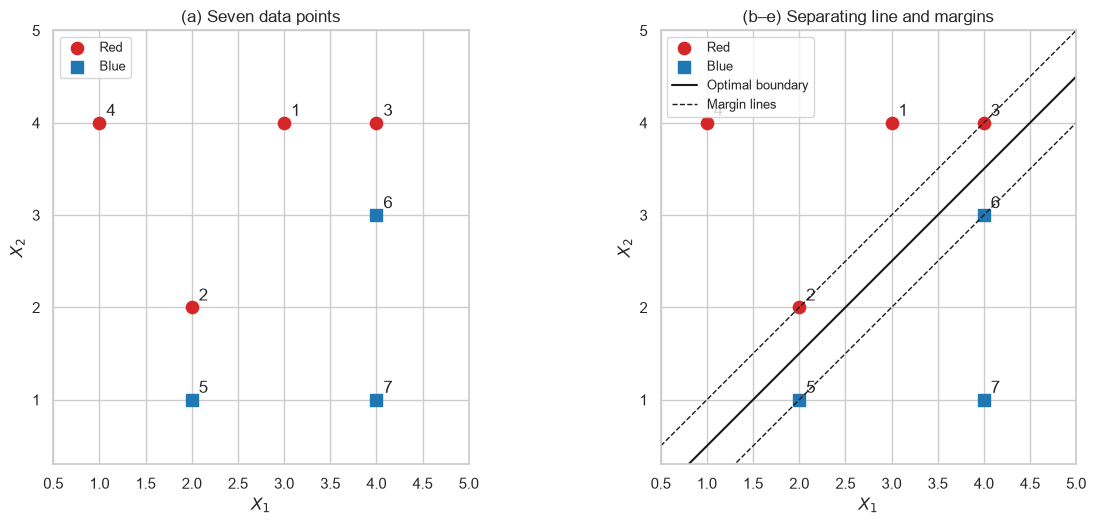

In [ ]:
points = pd.DataFrame({
    'obs':[1,2,3,4,5,6,7],
    'X1':[3,2,4,1,2,4,4],
    'X2':[4,2,4,4,1,3,1],
    'Label':['Red','Red','Red','Red','Blue','Blue','Blue']
})
display(points)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.4))
t = np.linspace(0.5, 5, 200)
for ax in axs:
    for color, marker in [('Red','o'), ('Blue','s')]:
        subset = points.query('Label == @color')
        ax.scatter(subset.X1, subset.X2, s=78, marker=marker,
                   color='tab:red' if color=='Red' else 'tab:blue', label=color)
        for _, r in subset.iterrows():
            ax.annotate(str(r.obs), (r.X1, r.X2), xytext=(5,5), textcoords='offset points')
    ax.set(xlim=(0.5,5), ylim=(0.3,5), xlabel='$X_1$', ylabel='$X_2$')
    ax.set_aspect('equal', adjustable='box')
axs[0].set_title('(a) Seven data points')
axs[1].plot(t,t-0.5,'k-',label='Optimal boundary')
axs[1].plot(t,t,'k--',lw=1,label='Margin lines')
axs[1].plot(t,t-1,'k--',lw=1)
axs[1].set_title('(b–e) Separating line and margins')
for ax in axs: ax.legend(fontsize=9,loc='upper left')
plt.tight_layout()
plt.show()

**(b)–(c)** The maximal-margin decision boundary is $X_2=X_1-0.5$, or $0.5-X_1+X_2=0$. I predict **Red** if $0.5-X_1+X_2>0$, and **Blue** otherwise. Thus $(\beta_0,\beta_1,\beta_2)=(0.5,-1,1)$.

**(d)–(e)** The two margin boundary lines are $X_2=X_1$ and $X_2=X_1-1$. The four support vectors are observations **2, 3, 5, and 6**. Their perpendicular distance to the central line is $0.5/\sqrt{2}\approx0.354$.

**(f)** Observation 7 is away from the margin. Moving it just a little will not move the optimal boundary, since it is not one of the support vectors.

**(g)** Another valid separator is $X_2=X_1-0.2$. It still separates the seven points but has a smaller margin, so it is not optimal.

**(h)** Add a Red point at $(3,2)$. That point is between the two Blue points $(2,1)$ and $(4,3)$. No straight line can put the added Red point on the Red side while keeping both of those Blue points on the Blue side.

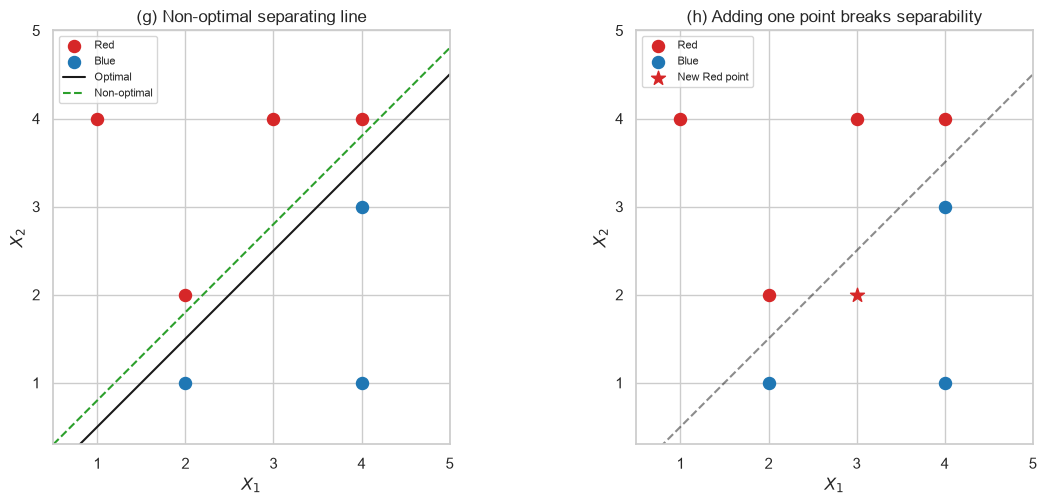

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(12,5.2))
for ax in axs:
    for color in ['Red','Blue']:
        s = points.query('Label == @color')
        ax.scatter(s.X1,s.X2,s=75, color='tab:red' if color=='Red' else 'tab:blue', label=color)
    ax.set(xlim=(0.5,5),ylim=(0.3,5),xlabel='$X_1$',ylabel='$X_2$')
    ax.set_aspect('equal',adjustable='box')
axs[0].plot(t,t-.5,'k-',label='Optimal')
axs[0].plot(t,t-.2, color='tab:green', linestyle='--', label='Non-optimal')
axs[0].set_title('(g) Non-optimal separating line')
axs[1].plot(t,t-.5,'k--',alpha=.5)
axs[1].scatter([3],[2],s=110,color='tab:red',marker='*',label='New Red point')
axs[1].set_title('(h) Adding one point breaks separability')
for ax in axs: ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

---
### References

- Homework 6 PDF provided by the instructor (DSCI 552).
- APS Failure at Scania Trucks, UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning with Applications in R*, 1st ed., Exercises 6.6.3, 6.6.5, 8.4.5, and 9.7.3: https://www.statlearning.com/
- scikit-learn documentation: https://scikit-learn.org/stable/
- imbalanced-learn documentation: https://imbalanced-learn.org/stable/
- XGBoost documentation: https://xgboost.readthedocs.io/en/stable/

*Parts labeled “Extra Practice” in the homework instructions are optional and are not included.*